# Last Mile Logistics Audit — Veridi Logistics

**Author:** Joshua Akintemi | **Date:** November 2026 | **Dataset:** Olist Brazilian E-Commerce (Kaggle)

Veridi's CEO suspects that negative reviews are driven by inaccurate delivery estimates, not just slow shipping. This notebook audits about 100,000 orders to test that idea and to answer her main question: are we failing specific regions, or is this a nationwide problem?

**Contents**
1. Loading the data
2. Building the master table
3. Calculating delivery delays
4. Late deliveries by state
5. Delays and review scores
6. Product categories in English
7. Candidate's Choice
8. Conclusion
9. Export for the dashboard

## 1. Loading the data

The dataset is downloaded straight from Kaggle with `kagglehub`, so the notebook runs anywhere without local file paths.

In [1]:
import os
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt


path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print("Files downloaded to:", path)
os.listdir(path)

ModuleNotFoundError: No module named 'pandas'

I load the three tables needed for the core analysis: orders, reviews and customers. The date columns are parsed as dates on load so they can be subtracted later.

In [ ]:
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders = pd.read_csv(os.path.join(path, "olist_orders_dataset.csv"), parse_dates=date_cols)
reviews = pd.read_csv(os.path.join(path, "olist_order_reviews_dataset.csv"))
customers = pd.read_csv(os.path.join(path, "olist_customers_dataset.csv"))


Before joining anything, I check how many rows each table has and whether its ID column is unique. A table with repeated IDs would multiply rows in a join.

In [ ]:
for name, df in [("orders", orders), ("reviews", reviews), ("customers", customers)]:
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

print("\nUnique order_id in orders:  ", orders["order_id"].nunique())
print("Unique order_id in reviews: ", reviews["order_id"].nunique())
print("Unique customer_id in customers:", customers["customer_id"].nunique())

orders: 99,441 rows, 8 columns
reviews: 99,224 rows, 7 columns
customers: 99,441 rows, 5 columns

Unique order_id in orders:   99441
Unique order_id in reviews:  98673
Unique customer_id in customers: 99441


**What this shows:** orders and customers match one-to-one (99,441 each). Reviews does not: 99,224 rows cover only 98,673 orders, so 551 rows are repeat reviews of the same order. Another 768 orders have no review at all.



A quick look at the first rows of each table to confirm the columns loaded as expected.

In [ ]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


## 2. Building the master table

### 2.1 One review per order

Some orders were reviewed more than once. To avoid duplicating orders in the join, I keep one review per order: the most recent one, since it reflects the customer's final opinion.

In [5]:
# Keep only the most recent review for each order
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

reviews_clean = (
    reviews
    .sort_values("review_answer_timestamp")
    .drop_duplicates(subset="order_id", keep="last")
    [["order_id", "review_score"]]
)

print(f"Reviews before: {len(reviews):,}")
print(f"Reviews after:  {len(reviews_clean):,}")
print(f"Removed:        {len(reviews) - len(reviews_clean):,}")

Reviews before: 99,224
Reviews after:  98,673
Removed:        551


### 2.2 Joining orders, customers and reviews

I join customers and reviews onto the orders table. A left join keeps every order, including those without a review.

In [6]:
# Join customers and reviews onto orders (one row per order)
master = (
    orders
    .merge(customers, on="customer_id", how="left", validate="one_to_one")
    .merge(reviews_clean, on="order_id", how="left", validate="one_to_one")
)

print(f"Orders table: {len(orders):,} rows")
print(f"Master table: {len(master):,} rows")

assert len(master) == len(orders), "Row count changed: the join duplicated rows."
print("Check passed: no duplicated rows.")

Orders table: 99,441 rows
Master table: 99,441 rows
Check passed: no duplicated rows.


### 2.3 Checking the result

Each row now holds one order together with its customer's state and review score.

In [7]:
# Preview the key columns of the master table
key_columns = [
    "order_id",
    "order_status",
    "customer_state",
    "review_score",
    "order_estimated_delivery_date",
    "order_delivered_customer_date",
]

master[key_columns].head()

,order_id,order_status,customer_state,review_score,order_estimated_delivery_date,order_delivered_customer_date
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,SP,4.0,2017-10-18,2017-10-10 21:25:13
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,BA,4.0,2018-08-13,2018-08-07 15:27:45
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,GO,5.0,2018-09-04,2018-08-17 18:06:29
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,RN,5.0,2017-12-15,2017-12-02 00:28:42
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,SP,5.0,2018-02-26,2018-02-16 18:17:02


## 3. Calculating delivery delays

### 3.1 Orders that were never delivered

Before measuring delays, I check order statuses and missing delivery dates. An order that never arrived cannot be classified as on time or late.

In [8]:
# Count orders by status and check for missing delivery dates
print("Orders by status:")
print(master["order_status"].value_counts().to_string())

missing_delivery = master["order_delivered_customer_date"].isna().sum()
print(f"\nOrders with no delivery date: {missing_delivery:,}")

Orders by status:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Orders with no delivery date: 2,965


**What this shows:** 2,965 orders have no delivery date. Most were never delivered. The count does not exactly match the 2,963 non-delivered orders, so I check the mismatch below before deciding what to exclude.

In [9]:
# Cross-check order status against the delivery date
is_delivered = master["order_status"] == "delivered"
has_date = master["order_delivered_customer_date"].notna()

print(f"Delivered, with a date:      {(is_delivered & has_date).sum():,}")
print(f"Delivered, but no date:      {(is_delivered & ~has_date).sum():,}")
print(f"Not delivered, with a date:  {(~is_delivered & has_date).sum():,}")
print(f"Not delivered, no date:      {(~is_delivered & ~has_date).sum():,}")

Delivered, with a date:      96,470
Delivered, but no date:      8
Not delivered, with a date:  6
Not delivered, no date:      2,957


**What this shows:** 8 orders are marked delivered but have no delivery date, and 6 orders have a delivery date but a non-delivered status (e.g. canceled). Both groups are inconsistent, so I exclude them. That leaves 96,470 orders to classify and 2,971 flagged as "Not Delivered".

### 3.2 Days difference and delivery status

`Days_Difference` = estimated delivery date − actual delivery date. A positive number means the order arrived early, zero means on the promised day, and a negative number means late.

Two decisions:
- **Only orders with status "delivered" and a delivery date are classified.** Everything else is flagged as "Not Delivered" and kept out of the late-rate calculations.
- **I compare calendar dates, not timestamps.** The estimate is a date with no time, so an order arriving at 3 pm on the promised day counts as on time.

Classification: **On Time** (0 or more), **Late** (1 to 5 days late), **Super Late** (more than 5 days late).

In [10]:
import numpy as np

# Days between the promised date and the actual delivery date (calendar days)
delivered_day = master["order_delivered_customer_date"].dt.normalize()
master["Days_Difference"] = (master["order_estimated_delivery_date"] - delivered_day).dt.days

# Classify each order
valid = (master["order_status"] == "delivered") & master["order_delivered_customer_date"].notna()

conditions = [
    ~valid,
    master["Days_Difference"] >= 0,
    master["Days_Difference"] >= -5,
]
labels = ["Not Delivered", "On Time", "Late"]

master["Delivery_Status"] = np.select(conditions, labels, default="Super Late")
master.loc[~valid, "Days_Difference"] = np.nan

### 3.3 How often do we miss the promised date?

In [11]:
# Share of each delivery status among delivered orders
delivered = master[master["Delivery_Status"] != "Not Delivered"]

summary = (
    delivered["Delivery_Status"]
    .value_counts()
    .reindex(["On Time", "Late", "Super Late"])
    .to_frame("Orders")
)
summary["Share (%)"] = (summary["Orders"] / len(delivered) * 100).round(1)

print(f"Delivered orders analysed: {len(delivered):,}")
print(f"Flagged as Not Delivered:  {(master['Delivery_Status'] == 'Not Delivered').sum():,}\n")
print(summary)

print(f"\nAverage days early (+) or late (-): {delivered['Days_Difference'].mean():.1f}")
print(f"Median:                             {delivered['Days_Difference'].median():.0f}")

Delivered orders analysed: 96,470
Flagged as Not Delivered:  2,971

                 Orders  Share (%)
Delivery_Status                   
On Time           89936       93.2
Late               2770        2.9
Super Late         3764        3.9

Average days early (+) or late (-): 11.9
Median:                             12


### 3.4 How far from the promise do orders arrive?

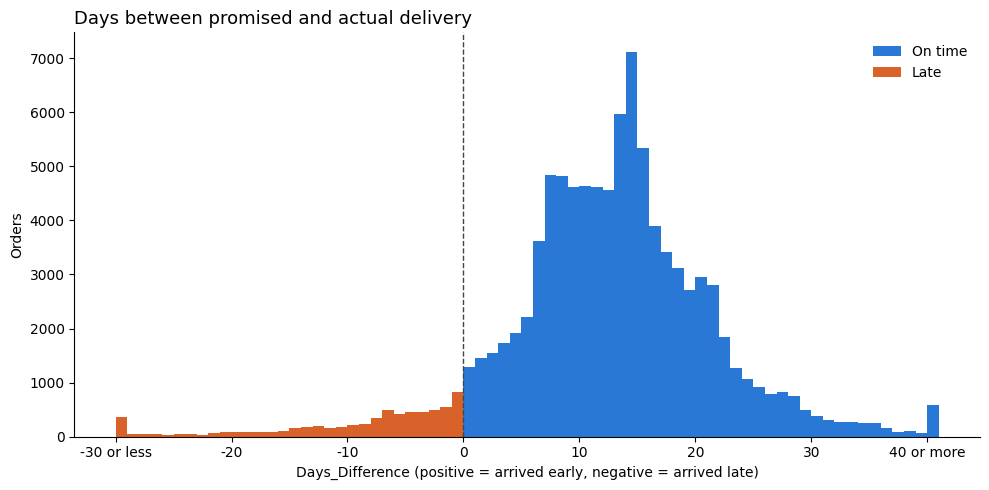

In [12]:
# Distribution of days early (+) or late (-)
values = delivered["Days_Difference"].clip(-30, 40)
bins = np.arange(-30, 42, 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(values[values >= 0], bins=bins, color="#2a78d6", label="On time")
ax.hist(values[values < 0], bins=bins, color="#d9622b", label="Late")
ax.axvline(0, color="#444444", linestyle="--", linewidth=1)

ax.set_title("Days between promised and actual delivery", loc="left", fontsize=13)
ax.set_xlabel("Days_Difference (positive = arrived early, negative = arrived late)")
ax.set_ylabel("Orders")
ax.set_xticks([-30, -20, -10, 0, 10, 20, 30, 40])
ax.set_xticklabels(["-30 or less", "-20", "-10", "0", "10", "20", "30", "40 or more"])
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What this shows:** most orders arrive 7 to 20 days before the promised date, with a peak around two weeks early. Late orders form a long tail to the left: fewer in number, but some arrive weeks after the estimate. The end bars group all orders beyond 30 days late or 40 days early.

## 4. Late deliveries by state

For each state, I calculate the share of delivered orders that arrived late (Late + Super Late). I also keep the order count, because a percentage from a state with very few orders is less reliable.

In [13]:
# Late rate per state
delivered = master[master["Delivery_Status"] != "Not Delivered"].copy()
delivered["Is_Late"] = delivered["Delivery_Status"].isin(["Late", "Super Late"])

state_stats = (
    delivered
    .groupby("customer_state")
    .agg(
        Orders=("order_id", "count"),
        Late_Orders=("Is_Late", "sum"),
        Avg_Days_Difference=("Days_Difference", "mean"),
    )
)
state_stats["Late_Rate_%"] = (state_stats["Late_Orders"] / state_stats["Orders"] * 100).round(1)
state_stats["Avg_Days_Difference"] = state_stats["Avg_Days_Difference"].round(1)
state_stats = state_stats.sort_values("Late_Rate_%", ascending=False)

national_rate = delivered["Is_Late"].mean() * 100
print(f"National late rate: {national_rate:.1f}%\n")
state_stats

National late rate: 6.8%



,Orders,Late_Orders,Avg_Days_Difference,Late_Rate_%
customer_state,,,,
AL,397,85,8.7,21.4
MA,717,125,9.6,17.4
SE,335,51,10.0,15.2
PI,476,66,11.3,13.9
CE,1279,176,10.8,13.8
BA,3256,396,10.8,12.2
RR,41,5,17.3,12.2
RJ,12350,1495,11.8,12.1
PA,946,106,14.1,11.2


### 4.1 Which states are worst?

The dashed line marks the national late rate, so states to its right perform worse than the country as a whole.

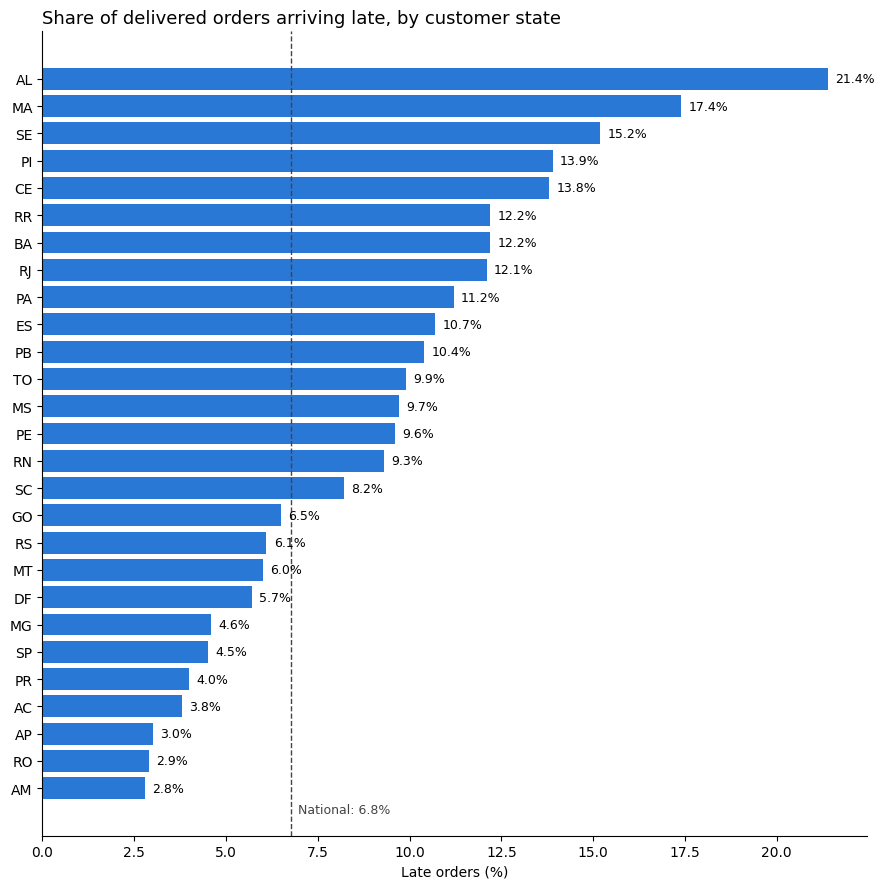

In [14]:
import matplotlib.pyplot as plt

# Horizontal bar chart of late rate by state
plot_data = state_stats.sort_values("Late_Rate_%")

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(plot_data.index, plot_data["Late_Rate_%"], color="#2a78d6")
ax.axvline(national_rate, color="#444444", linestyle="--", linewidth=1)
ax.text(national_rate + 0.2, -0.9, f"National: {national_rate:.1f}%", color="#444444", fontsize=9)

for i, value in enumerate(plot_data["Late_Rate_%"]):
    ax.text(value + 0.2, i, f"{value}%", va="center", fontsize=9)

ax.set_title("Share of delivered orders arriving late, by customer state", loc="left", fontsize=13)
ax.set_xlabel("Late orders (%)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What this shows:**
- Late rates vary from 2.8% (AM) to 21.4% (AL), so this is a regional problem, not a nationwide one.
- The worst states are concentrated in the Northeast: AL, MA, SE, PI, CE and BA are all at 12% or more.
- Rio de Janeiro stands out by volume: 12.1% late on 12,350 orders, which is 1,495 late deliveries.
- RR, AP and AC have fewer than 100 orders each (41, 67 and 80), so their rates should be read with caution.


### 4.2 Are remote states disproportionately affected?

The dataset has no single distribution centre, so I first check where sellers are located. I then group states into Brazil's five regions to compare those near the sellers with those far away.

In [15]:
# Where do orders ship from?
sellers = pd.read_csv(os.path.join(path, "olist_sellers_dataset.csv"))

seller_share = (sellers["seller_state"].value_counts(normalize=True) * 100).round(1)
print("Share of sellers by state (top 5):")
print(seller_share.head().to_string())

Share of sellers by state (top 5):
seller_state
SP    59.7
PR    11.3
MG     7.9
SC     6.1
RJ     5.5


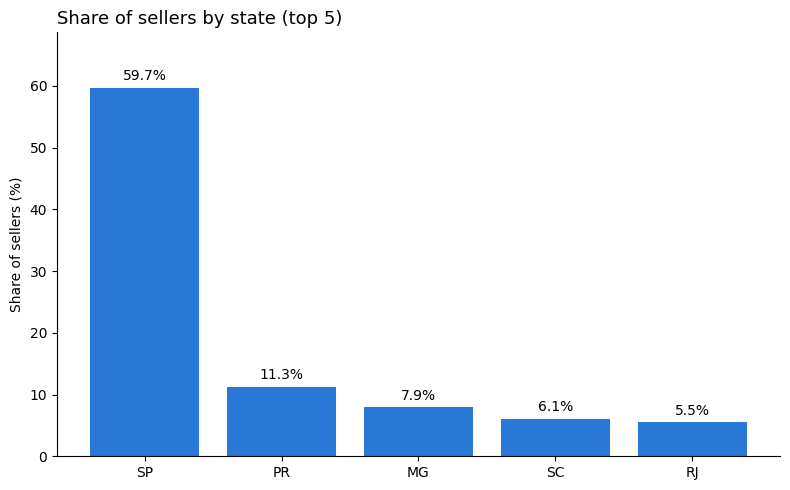

In [16]:
# Chart: share of sellers by state (top 5)
top5 = seller_share.head(5)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(top5.index, top5.values, color="#2a78d6")
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=10)

ax.set_title("Share of sellers by state (top 5)", loc="left", fontsize=13)
ax.set_ylabel("Share of sellers (%)")
ax.set_ylim(0, top5.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [17]:
# Map each state to its region
region_map = {
    "AC": "North", "AP": "North", "AM": "North", "PA": "North",
    "RO": "North", "RR": "North", "TO": "North",
    "AL": "Northeast", "BA": "Northeast", "CE": "Northeast", "MA": "Northeast",
    "PB": "Northeast", "PE": "Northeast", "PI": "Northeast", "RN": "Northeast", "SE": "Northeast",
    "DF": "Central-West", "GO": "Central-West", "MT": "Central-West", "MS": "Central-West",
    "ES": "Southeast", "MG": "Southeast", "RJ": "Southeast", "SP": "Southeast",
    "PR": "South", "RS": "South", "SC": "South",
}
master["Region"] = master["customer_state"].map(region_map)
delivered["Region"] = delivered["customer_state"].map(region_map)

# Delivery time in days, from purchase to arrival
delivered["Delivery_Days"] = (
    delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]
).dt.days

region_stats = (
    delivered
    .groupby("Region")
    .agg(
        Orders=("order_id", "count"),
        Late_Rate=("Is_Late", "mean"),
        Avg_Delivery_Days=("Delivery_Days", "mean"),
        Avg_Days_Early=("Days_Difference", "mean"),
    )
)
region_stats["Late_Rate_%"] = (region_stats["Late_Rate"] * 100).round(1)
region_stats = region_stats.drop(columns="Late_Rate").round(1).sort_values("Late_Rate_%", ascending=False)
region_stats

,Orders,Avg_Delivery_Days,Avg_Days_Early,Late_Rate_%
Region,,,,
Northeast,9044,19.5,11.3,12.7
North,1796,22.1,15.6,8.6
Central-West,5624,14.6,12.3,6.5
Southeast,66193,10.3,11.6,6.1
South,13813,13.6,13.1,5.9


**What this shows:**
- About 60% of sellers are in São Paulo, so the Southeast acts as the distribution hub.
- Remote regions are disproportionately affected: the Northeast is late 12.7% of the time and the North 8.6%, compared with about 6% in the Southeast, South and Central-West.
- Distance alone is not the cause. The North has the longest delivery time (22.1 days) but a lower late rate than the Northeast (19.5 days), because its estimates include a larger cushion (15.6 days vs 11.3).
- The Northeast gets almost the same cushion as the Southeast, although shipping there takes nearly twice as long. Its delivery estimates are too optimistic.

In [18]:
focus = delivered[(delivered["Region"] == "Northeast") | (delivered["customer_state"] == "RJ")]
print(f"Northeast + RJ: {len(focus) / len(delivered) * 100:.0f}% of orders, "
      f"{focus['Is_Late'].sum() / delivered['Is_Late'].sum() * 100:.0f}% of late orders")

Northeast + RJ: 22% of orders, 40% of late orders


## 5. Delays and review scores

### 5.1  Review score by delivery status

I compare the average review score for On Time, Late and Super Late orders, along with the share of 1-star reviews in each group. Orders without a review are left out.

In [19]:
# Review scores by delivery status
reviewed = delivered.dropna(subset=["review_score"]).copy()
reviewed["Is_One_Star"] = reviewed["review_score"] == 1

status_reviews = (
    reviewed
    .groupby("Delivery_Status")
    .agg(
        Orders=("order_id", "count"),
        Avg_Review_Score=("review_score", "mean"),
        One_Star_Share=("Is_One_Star", "mean"),
    )
    .reindex(["On Time", "Late", "Super Late"])
)
status_reviews["Avg_Review_Score"] = status_reviews["Avg_Review_Score"].round(2)
status_reviews["One_Star_%"] = (status_reviews["One_Star_Share"] * 100).round(1)
status_reviews = status_reviews.drop(columns="One_Star_Share")

all_late = reviewed[reviewed["Is_Late"]]["review_score"].mean()
print(f"Average score, all late orders (Late + Super Late): {all_late:.2f}\n")
status_reviews

Average score, all late orders (Late + Super Late): 2.27



,Orders,Avg_Review_Score,One_Star_%
Delivery_Status,,,
On Time,89443,4.29,6.6
Late,2722,2.99,33.6
Super Late,3659,1.74,68.8


### 5.2 On Time vs Late, side by side

In [20]:
# Direct comparison: On Time vs all Late orders (Late + Super Late)
reviewed["On_Time_vs_Late"] = np.where(reviewed["Is_Late"], "Late", "On Time")

comparison = (
    reviewed
    .groupby("On_Time_vs_Late")
    .agg(Orders=("order_id", "count"), Avg_Review_Score=("review_score", "mean"))
    .round(2)
    .reindex(["On Time", "Late"])
)
comparison

,Orders,Avg_Review_Score
On_Time_vs_Late,,
On Time,89443,4.29
Late,6381,2.27


### 5.3 Review score by size of the delay

To see how the score changes as the delay grows, I group orders by how many days early or late they arrived.

                 Orders  Avg_Review_Score
Delay_Group                              
15+ days early    34771              4.32
8-14 days early   36158              4.31
1-7 days early    17234              4.20
On the day         1280              4.03
1-3 days late      1852              3.29
4-7 days late      1748              2.10
8-14 days late     1446              1.67
15+ days late      1335              1.72


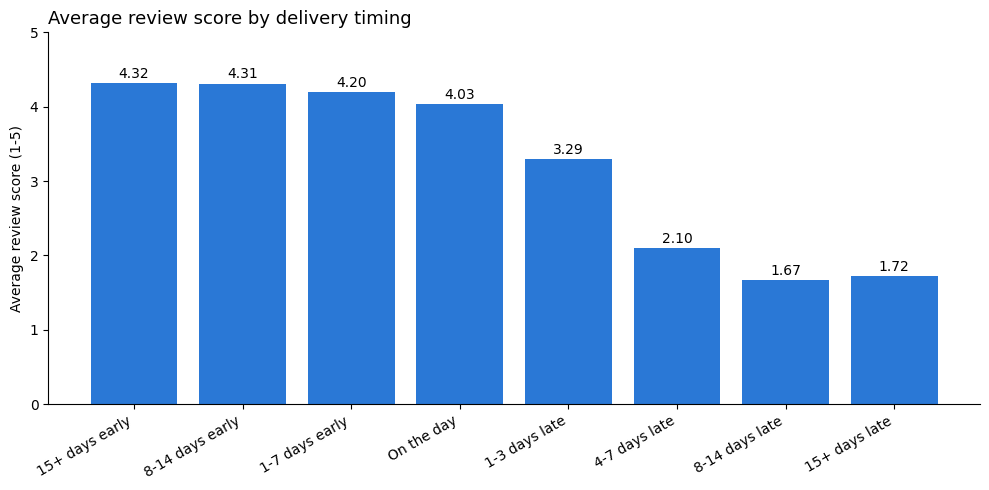

In [21]:
# Group orders by how early or late they arrived
bins = [-np.inf, -15, -8, -4, -1, 0, 7, 14, np.inf]
labels = [
    "15+ days late", "8-14 days late", "4-7 days late", "1-3 days late",
    "On the day", "1-7 days early", "8-14 days early", "15+ days early",
]
reviewed["Delay_Group"] = pd.cut(reviewed["Days_Difference"], bins=bins, labels=labels)

delay_reviews = (
    reviewed
    .groupby("Delay_Group", observed=True)
    .agg(Orders=("order_id", "count"), Avg_Review_Score=("review_score", "mean"))
    .round(2)
    .iloc[::-1]   # order from earliest to latest
)
print(delay_reviews)

# Bar chart
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(delay_reviews.index.astype(str), delay_reviews["Avg_Review_Score"], color="#2a78d6")

for i, value in enumerate(delay_reviews["Avg_Review_Score"]):
    ax.text(i, value + 0.07, f"{value:.2f}", ha="center", fontsize=10)

ax.set_title("Average review score by delivery timing", loc="left", fontsize=13)
ax.set_ylabel("Average review score (1-5)")
ax.set_ylim(0, 5)
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 5.4 Review score for each day of delay

The same relationship day by day. Negative values are days early, positive values are days late. Days with fewer than 30 orders are left out so that single reviews do not distort the line.

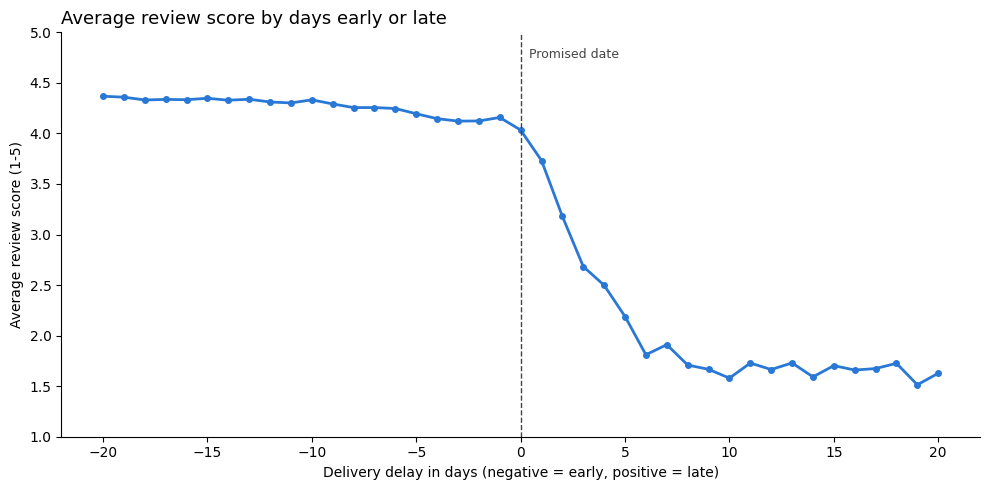

Correlation between delay (days) and review score: -0.27


In [22]:
# Average review score for each day early (-) or late (+)
reviewed["Delay_Days"] = -reviewed["Days_Difference"]

daily = (
    reviewed[reviewed["Delay_Days"].between(-20, 20)]
    .groupby("Delay_Days")
    .agg(Orders=("order_id", "count"), Avg_Review_Score=("review_score", "mean"))
)
daily = daily[daily["Orders"] >= 30]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(daily.index, daily["Avg_Review_Score"], color="#2a78d6", linewidth=2, marker="o", markersize=4)
ax.axvline(0, color="#444444", linestyle="--", linewidth=1)
ax.text(0.4, 4.75, "Promised date", color="#444444", fontsize=9)

ax.set_title("Average review score by days early or late", loc="left", fontsize=13)
ax.set_xlabel("Delivery delay in days (negative = early, positive = late)")
ax.set_ylabel("Average review score (1-5)")
ax.set_ylim(1, 5)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

correlation = reviewed["Delay_Days"].corr(reviewed["review_score"])
print(f"Correlation between delay (days) and review score: {correlation:.2f}")

**What this shows:**
- On-time orders average 4.29 stars; late orders average 2.27, a gap of two full stars.
- The promised date is a clear turning point. Scores stay near 4.3 for early deliveries, then fall from 4.0 on the promised day to about 1.8 within six days.
- After roughly a week late, scores level off around 1.7. By then the customer's opinion is already lost, so the first few days after a missed deadline matter most.
- 1-star reviews rise from 6.6% of on-time orders to 33.6% of late and 68.8% of super late orders.
- Arriving much earlier than promised adds almost nothing: orders 15+ days early score 4.32, against 4.20 for orders 1-7 days early.
- The overall correlation between delay and review score is modest (-0.27). Most orders arrive early and score well regardless of how early, so the effect is concentrated after the promised date, as the chart shows.

This is strong evidence that missed delivery promises drive bad reviews. It is an association, not proof of causation, since factors such as product quality also affect scores. But the drop begins exactly at the promised date and deepens with each day of delay, which makes late delivery the most likely main driver.

### 5.5 Did late deliveries and bad reviews spike together?

The CEO noticed a spike in negative reviews. Here I track the late rate and the average review score by purchase month. Months with fewer than 500 orders are left out.

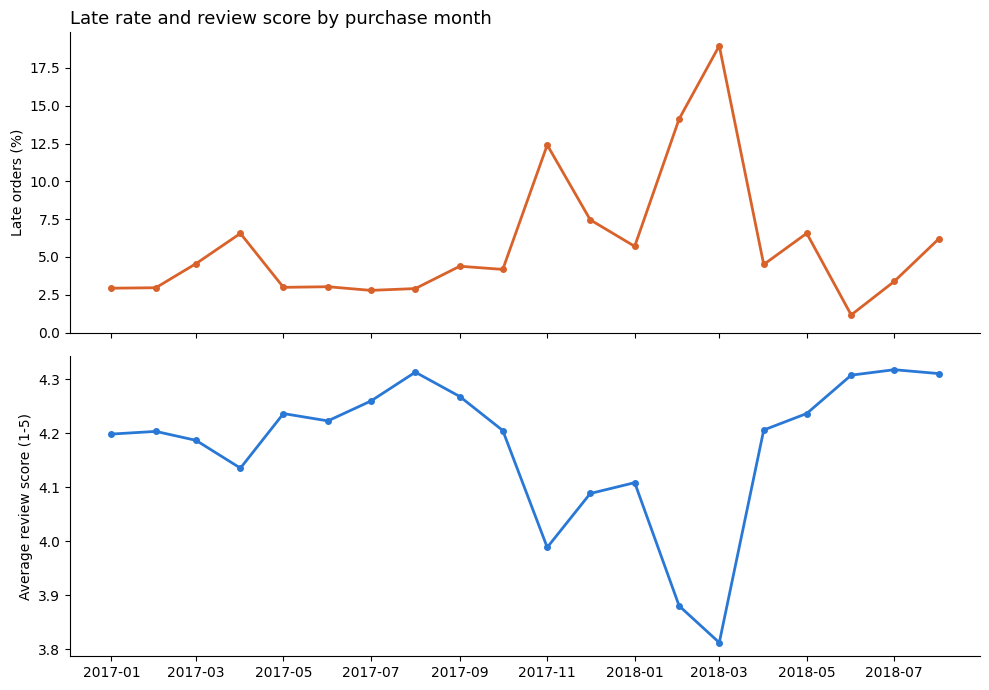

                Orders  Late_Rate_%  Avg_Review_Score
Purchase_Month                                       
2017-01-01         750         2.93              4.20
2017-02-01        1653         2.96              4.20
2017-03-01        2546         4.56              4.19
2017-04-01        2303         6.56              4.14
2017-05-01        3545         2.99              4.24
2017-06-01        3135         3.03              4.22
2017-07-01        3872         2.79              4.26
2017-08-01        4193         2.91              4.31
2017-09-01        4150         4.39              4.27
2017-10-01        4478         4.18              4.20
2017-11-01        7288        12.40              3.99
2017-12-01        5513         7.46              4.09
2018-01-01        7069         5.70              4.11
2018-02-01        6555        14.13              3.88
2018-03-01        7003        18.96              3.81
2018-04-01        6798         4.50              4.21
2018-05-01        6749      

In [23]:
# Monthly late rate and average review score
delivered["Purchase_Month"] = delivered["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()

monthly = (
    delivered
    .groupby("Purchase_Month")
    .agg(Orders=("order_id", "count"), Late_Rate=("Is_Late", "mean"), Avg_Review_Score=("review_score", "mean"))
)
monthly = monthly[monthly["Orders"] >= 500]
monthly["Late_Rate_%"] = monthly["Late_Rate"] * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

ax1.plot(monthly.index, monthly["Late_Rate_%"], color="#d9622b", linewidth=2, marker="o", markersize=4)
ax1.set_title("Late rate and review score by purchase month", loc="left", fontsize=13)
ax1.set_ylabel("Late orders (%)")
ax1.set_ylim(0)

ax2.plot(monthly.index, monthly["Avg_Review_Score"], color="#2a78d6", linewidth=2, marker="o", markersize=4)
ax2.set_ylabel("Average review score (1-5)")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

print(monthly[["Orders", "Late_Rate_%", "Avg_Review_Score"]].round(2))

**What this shows:**
- The late rate and the review score move in opposite directions month by month.
- There are two spikes. In November 2017 the late rate rose to 12.4% as orders jumped from about 4,500 to 7,300, consistent with a Black Friday surge. In February and March 2018 it reached 14.1% and 19.0% with no rise in volume, and the review score fell to 3.81, its lowest point.
- Scores recovered as soon as deliveries did: by June 2018 the late rate was 1.2% and the score 4.31.
- This is the spike in negative reviews the CEO noticed. The problem is concentrated in specific months as well as specific regions. The data does not explain the cause of the early 2018 episode, which deserves investigation.

## 6. Product categories in English

Category names are in Portuguese, so I translate them using the translation file included in the dataset. An order can contain several items; to keep one row per order, I use the category of the first item. Two categories are missing from the translation file and are translated manually.

In [24]:
# Load the product tables
items = pd.read_csv(os.path.join(path, "olist_order_items_dataset.csv"))
products = pd.read_csv(os.path.join(path, "olist_products_dataset.csv"))
translation = pd.read_csv(
    os.path.join(path, "product_category_name_translation.csv"), encoding="utf-8-sig"
)

# One category per order: the first item in the order
order_category = (
    items[items["order_item_id"] == 1][["order_id", "product_id"]]
    .merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
    .merge(translation, on="product_category_name", how="left")
)

# Categories that the translation file does not cover
manual_translation = {
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_food_processors",
}
order_category["Category"] = (
    order_category["product_category_name_english"]
    .fillna(order_category["product_category_name"].map(manual_translation))
    .fillna("unknown")
)
order_category = order_category[["order_id", "Category"]]

# Add the category to the master and delivered tables
rows_before = len(master)
master = master.merge(order_category, on="order_id", how="left", validate="one_to_one")
delivered = delivered.merge(order_category, on="order_id", how="left", validate="one_to_one")
master["Category"] = master["Category"].fillna("unknown")
delivered["Category"] = delivered["Category"].fillna("unknown")

assert len(master) == rows_before, "Row count changed: the join duplicated rows."
print(f"Master table: {len(master):,} rows (unchanged)")
print(f"Distinct categories: {master['Category'].nunique()}")
print(f"Orders with unknown category: {(master['Category'] == 'unknown').sum():,}")

Master table: 99,441 rows (unchanged)
Distinct categories: 74
Orders with unknown category: 2,191


### 6.1 Checking the translation

A sample of the mapping, including the example from the brief (`cama_mesa_banho`).

In [25]:
# Show Portuguese names next to their English translation
examples = ["cama_mesa_banho", "beleza_saude", "moveis_escritorio", "eletronicos", "pc_gamer"]

translation_check = (
    products[["product_category_name"]]
    .drop_duplicates()
    .merge(translation, on="product_category_name", how="left")
)
translation_check["product_category_name_english"] = translation_check[
    "product_category_name_english"
].fillna(translation_check["product_category_name"].map(manual_translation))

translation_check = translation_check.rename(columns={
    "product_category_name": "Portuguese (original)",
    "product_category_name_english": "English (translated)",
})

untranslated = translation_check["English (translated)"].isna().sum() - translation_check["Portuguese (original)"].isna().sum()
print(f"Categories left without a translation: {untranslated}\n")
translation_check[translation_check["Portuguese (original)"].isin(examples)]

Categories left without a translation: 0



,Portuguese (original),English (translated)
10,cama_mesa_banho,bed_bath_table
13,beleza_saude,health_beauty
16,moveis_escritorio,office_furniture
18,eletronicos,electronics
64,pc_gamer,pc_gamer


### 6.2 Which categories are hardest to deliver on time?

Only categories with at least 500 delivered orders are shown, so the rates are reliable.

In [26]:
# Late rate and review score by category
category_stats = (
    delivered
    .groupby("Category")
    .agg(
        Orders=("order_id", "count"),
        Late_Rate=("Is_Late", "mean"),
        Avg_Review_Score=("review_score", "mean"),
    )
)
category_stats = category_stats[category_stats["Orders"] >= 500]
category_stats["Late_Rate_%"] = (category_stats["Late_Rate"] * 100).round(1)
category_stats["Avg_Review_Score"] = category_stats["Avg_Review_Score"].round(2)
category_stats = category_stats.drop(columns="Late_Rate").sort_values("Late_Rate_%", ascending=False)

print(f"Categories with 500+ orders: {len(category_stats)}\n")
print("Highest late rates:")
print(category_stats.head(8))
print("\nLowest late rates:")
print(category_stats.tail(5))

Categories with 500+ orders: 26

Highest late rates:
                                 Orders  Avg_Review_Score  Late_Rate_%
Category                                                              
baby                               2763              4.12          8.2
office_furniture                   1246              3.65          8.1
electronics                        2507              4.13          7.7
musical_instruments                 607              4.25          7.6
bed_bath_table                     9167              4.01          7.5
health_beauty                      8608              4.23          7.5
watches_gifts                      5470              4.13          7.4
construction_tools_construction     728              4.13          7.4

Lowest late rates:
                     Orders  Avg_Review_Score  Late_Rate_%
Category                                                  
housewares             5688              4.20          5.4
pet_shop               1682             

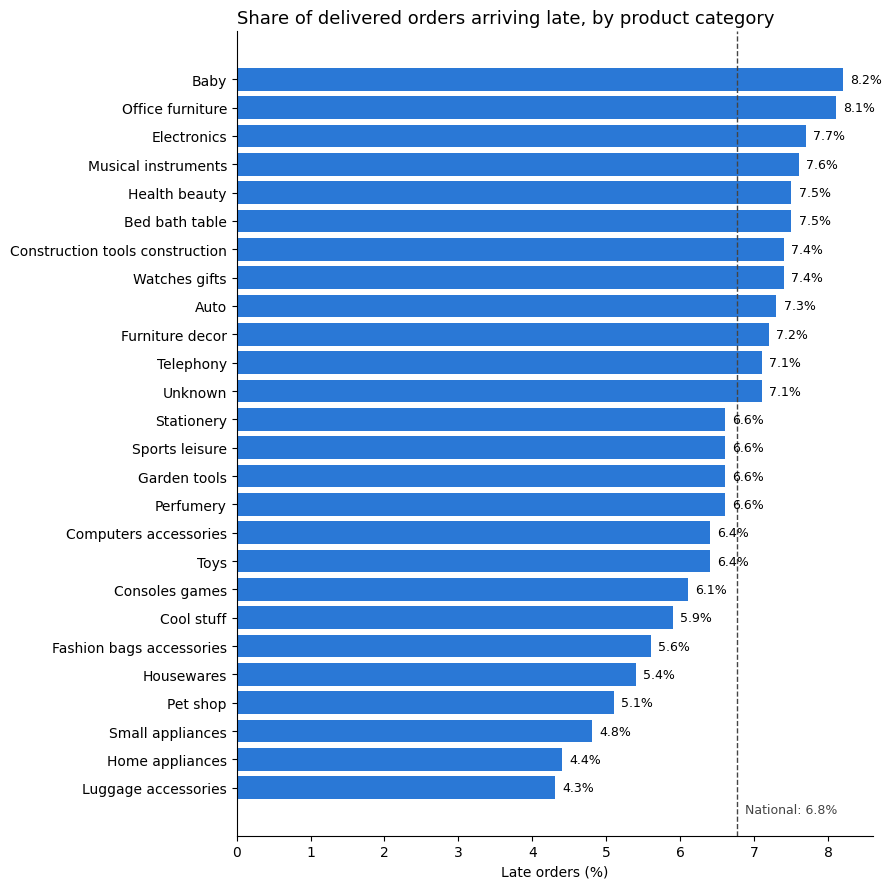

In [27]:
# Late rate by product category (English names)
plot_data = category_stats.sort_values("Late_Rate_%")
plot_labels = plot_data.index.str.replace("_", " ").str.capitalize()

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(plot_labels, plot_data["Late_Rate_%"], color="#2a78d6")
ax.axvline(national_rate, color="#444444", linestyle="--", linewidth=1)
ax.text(national_rate + 0.1, -0.9, f"National: {national_rate:.1f}%", color="#444444", fontsize=9)

for i, value in enumerate(plot_data["Late_Rate_%"]):
    ax.text(value + 0.1, i, f"{value}%", va="center", fontsize=9)

ax.set_title("Share of delivered orders arriving late, by product category", loc="left", fontsize=13)
ax.set_xlabel("Late orders (%)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 6.3 Is furniture harder to ship than electronics?

In [28]:
# Group related categories and compare
furniture = delivered["Category"].str.contains("furniture")
electronics = delivered["Category"].isin(
    ["electronics", "computers_accessories", "telephony", "computers", "tablets_printing_image"]
)

delivered["Product_Group"] = np.select([furniture, electronics], ["Furniture", "Electronics"], default="Other")

group_stats = (
    delivered
    .groupby("Product_Group")
    .agg(
        Orders=("order_id", "count"),
        Late_Rate=("Is_Late", "mean"),
        Avg_Delivery_Days=("Delivery_Days", "mean"),
        Avg_Review_Score=("review_score", "mean"),
    )
    .reindex(["Furniture", "Electronics", "Other"])
)
group_stats["Late_Rate_%"] = (group_stats["Late_Rate"] * 100).round(1)
group_stats = group_stats.drop(columns="Late_Rate").round(2)
group_stats

,Orders,Avg_Delivery_Days,Avg_Review_Score,Late_Rate_%
Product_Group,,,,
Furniture,8233,13.80,4.01,7.3
Electronics,13336,12.62,4.09,6.9
Other,74901,11.81,4.18,6.7


**What this shows:**
- All categories are translated into English; two that were missing from the translation file were mapped manually. "Unknown" covers 2,191 orders with no item record or no product category.
- Furniture is slightly harder to ship than electronics: 7.3% late vs 6.9%, and 13.8 days to deliver vs 12.6. Furniture also scores lower in reviews (4.01 vs 4.09). The gap is real but small.
- Product category matters far less than location. Late rates range from 4.3% to 8.2% across categories, compared with 2.8% to 21.4% across states.
- Office furniture has the lowest review score of the large categories (3.65) while its late rate (8.1%) is similar to electronics. Lateness alone does not explain it, so it deserves a separate look.

## 7. Candidate's Choice: recalibrating the delivery promise

The audit shows that bad reviews follow missed promises, and that some states get much less cushion in their estimates than others. This section turns that into an action: for each state, how many days should be added to (or could be removed from) the delivery estimate so that 95% of orders arrive on or before the promised date?

**Method:** for each state I take the 95th percentile of the delay in days. If 95% of orders arrive no more than X days after the current estimate, then adding X days would have brought that state to 95% on time. States with fewer than 200 orders are left out.

In [29]:
# Days to add (+) or remove (-) per state to reach 95% on-time delivery
TARGET = 0.95
delivered["Delay_Days"] = -delivered["Days_Difference"]

recalibration = (
    delivered
    .groupby("customer_state")
    .agg(
        Orders=("order_id", "count"),
        Current_Late_Rate=("Is_Late", "mean"),
        Avg_Days_Early=("Days_Difference", "mean"),
        Days_To_Adjust=("Delay_Days", lambda x: x.quantile(TARGET)),
    )
)
recalibration = recalibration[recalibration["Orders"] >= 200]
recalibration["Current_Late_%"] = (recalibration["Current_Late_Rate"] * 100).round(1)
recalibration["Avg_Days_Early"] = recalibration["Avg_Days_Early"].round(1)
recalibration["Days_To_Adjust"] = np.ceil(recalibration["Days_To_Adjust"]).astype(int)
recalibration = (
    recalibration
    .drop(columns="Current_Late_Rate")
    .sort_values("Days_To_Adjust", ascending=False)
)
recalibration

,Orders,Avg_Days_Early,Days_To_Adjust,Current_Late_%
customer_state,,,,
AL,397,8.7,13,21.4
CE,1279,10.8,13,13.8
MA,717,9.6,13,17.4
RJ,12350,11.8,12,12.1
SE,335,10.0,12,15.2
PA,946,14.1,10,11.2
BA,3256,10.8,9,12.2
PI,476,11.3,9,13.9
PE,1593,13.3,9,9.6


### 7.1 What would this change?

I replay the historical orders with longer estimates for the states that need them. Estimates are only extended, never shortened, to keep the simulation cautious.

In [30]:
# Replay history: extend estimates only in states below the 95% target
days_to_add = recalibration["Days_To_Adjust"].clip(lower=0)
delivered["Added_Days"] = delivered["customer_state"].map(days_to_add).fillna(0)
delivered["Late_After"] = delivered["Delay_Days"] > delivered["Added_Days"]

late_before = delivered["Is_Late"].sum()
late_after = delivered["Late_After"].sum()

print(f"States needing a longer estimate: {(days_to_add > 0).sum()} of {len(days_to_add)}")
print(f"Late orders before: {late_before:,} ({late_before / len(delivered) * 100:.1f}%)")
print(f"Late orders after:  {late_after:,} ({late_after / len(delivered) * 100:.1f}%)")
print(f"Broken promises avoided: {late_before - late_after:,}")

States needing a longer estimate: 19 of 23
Late orders before: 6,534 (6.8%)
Late orders after:  4,391 (4.6%)
Broken promises avoided: 2,143


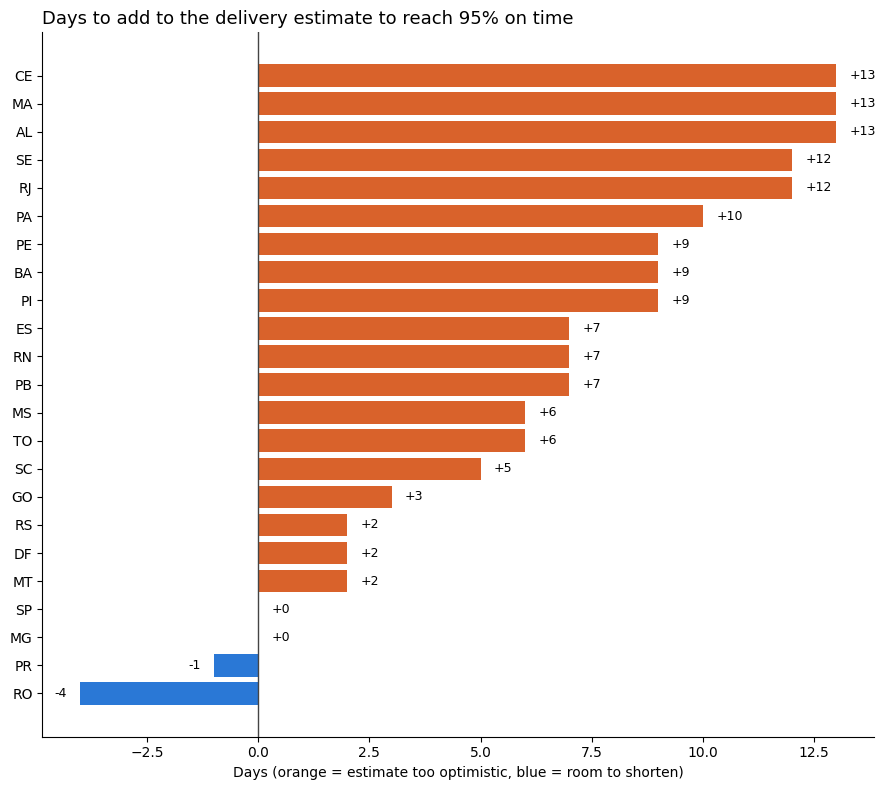

In [31]:
# Chart: adjustment needed per state
plot_data = recalibration.sort_values("Days_To_Adjust")
colors = ["#d9622b" if d > 0 else "#2a78d6" for d in plot_data["Days_To_Adjust"]]

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(plot_data.index, plot_data["Days_To_Adjust"], color=colors)
ax.axvline(0, color="#444444", linewidth=1)

for i, value in enumerate(plot_data["Days_To_Adjust"]):
    offset = 0.3 if value >= 0 else -0.3
    ax.text(value + offset, i, f"{value:+d}", va="center", ha="left" if value >= 0 else "right", fontsize=9)

ax.set_title("Days to add to the delivery estimate to reach 95% on time", loc="left", fontsize=13)
ax.set_xlabel("Days (orange = estimate too optimistic, blue = room to shorten)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What this shows:**
- 19 of 23 states would need a longer estimate to reach 95% on time. São Paulo and Minas Gerais need no change; Paraná and Rondônia have room to shorten.
- The largest gaps are in the Northeast and in Rio de Janeiro: +12 to +13 days in AL, MA, CE, SE and RJ.
- Replaying past orders with these longer estimates would have avoided 2,143 broken promises, cutting the national late rate from 6.8% to 4.6%.
- The size of the adjustments is a finding in itself. These states already receive most orders well ahead of the estimate, so the problem is a minority of orders that arrive very late, not the typical delivery. Longer estimates alone cannot fully cover that.

**Why this matters to the business:** Section 5 showed that a broken promise costs about two review stars, while arriving earlier than promised earns almost nothing. This table shows where to act first and by how much. I would treat the figures as an upper bound: extend estimates moderately in the worst states, and investigate the very late orders there, starting with Rio de Janeiro because of its volume.

**Limits:** this is a replay of past orders, not a forecast. It assumes delivery times stay the same and that longer estimates do not discourage customers from buying.

## 8. Conclusion:

**Is this a regional or a nationwide problem?** Regional, and concentrated in time. Nationally, 93.2% of orders arrive on time, but late rates range from 2.8% to 21.4% by state. The Northeast (12.7% late) and Rio de Janeiro (12.1%) are hit hardest: together they receive 22% of orders but account for about 40% of all late deliveries.

**Are the delivery estimates inaccurate?** Yes, in two ways. The typical order arrives 12 days before the estimate, so most promises are too cautious. But in the Northeast and Rio de Janeiro the same cushion is not enough, and a minority of orders arrive very late.

**Does this explain the bad reviews?** The evidence is strong. On-time orders average 4.29 stars and late orders 2.27, and the drop begins exactly at the promised date. Month by month, review scores fell whenever late deliveries rose, reaching their lowest point (3.81) in March 2018 when 19% of orders were late.



## 9. Export for the dashboard

In [32]:
# Build the dashboard table: one row per order
export = master.copy()

is_classified = export["Delivery_Status"] != "Not Delivered"
export["Is_Late"] = np.where(is_classified, export["Delivery_Status"].isin(["Late", "Super Late"]).astype(int), np.nan)
export["Delay_Days"] = -export["Days_Difference"]
export["Delivery_Days"] = (
    export["order_delivered_customer_date"] - export["order_purchase_timestamp"]
).dt.days.where(is_classified)
export["State_ISO"] = "BR-" + export["customer_state"]
export["Purchase_Date"] = export["order_purchase_timestamp"].dt.date
export["Category"] = export["Category"].str.replace("_", " ").str.capitalize()

export = export[[
    "order_id", "Purchase_Date", "order_status",
    "customer_state", "State_ISO", "Region", "Category",
    "Delivery_Status", "Is_Late", "Days_Difference", "Delay_Days", "Delivery_Days",
    "review_score",
]]

export.to_csv("veridi_delivery_audit.csv", index=False)
print(f"Saved {len(export):,} rows and {export.shape[1]} columns to veridi_delivery_audit.csv")
export.head()

Saved 99,441 rows and 13 columns to veridi_delivery_audit.csv


,order_id,Purchase_Date,order_status,customer_state,State_ISO,Region,Category,Delivery_Status,Is_Late,Days_Difference,Delay_Days,Delivery_Days,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02,delivered,SP,BR-SP,Southeast,Housewares,On Time,0.0,8.0,-8.0,8.0,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24,delivered,BA,BR-BA,Northeast,Perfumery,On Time,0.0,6.0,-6.0,13.0,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08,delivered,GO,BR-GO,Central-West,Auto,On Time,0.0,18.0,-18.0,9.0,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18,delivered,RN,BR-RN,Northeast,Pet shop,On Time,0.0,13.0,-13.0,13.0,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13,delivered,SP,BR-SP,Southeast,Stationery,On Time,0.0,10.0,-10.0,2.0,5.0


In [33]:
# Download the file when running in Google Colab
try:
    from google.colab import files
    files.download("veridi_delivery_audit.csv")
except ImportError:
    print("Not running in Colab: the file is saved next to this notebook.")